# Epoch validation

If we do a simple block average across conditions, do we get a consistent HRF?

The timing error will change between subjects. The error is a fixed unknown amount of seconds. That is, every condition will be shifted by the same amount. Consider every condition together and check that we have some HRF shape.


In [1]:
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd
from nilearn.glm.first_level.hemodynamic_models import compute_regressor

In [2]:
PRE_TRIAL_SEC  = 2.0    # baseline window before trial onset
TRIAL_DUR_SEC  = 5.0    # nominal stimulus duration
POST_TRIAL_SEC = 15.0   # tail after trial onset (covers 5 s stim + HRF return)

ROI_PAIRS = {
    'PFC_ALL': {(2,1),(2,3),(1,1),(1,2),(4,2),(4,4),(4,5),
                (7,5),(7,7),(8,7),(8,6),(5,6),(5,3),(5,4),
                (3,3),(3,2),(3,4),(6,6),(6,5),(6,4)},
}
ROI_ORDER = ['PFC_ALL']

# Task annotation labels — used to identify which events to epoch
CONDITIONS = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']

task      = 'lettersearch'
bids_root = 'data/lettersearch_BIDS'
datatype  = 'nirs'

bids_folder  = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files   = bids_folder.match()
all_subjects = sorted({f.subject for f in nirs_files})

offsets_path = 'data/trigger_offsets.csv'
if os.path.exists(offsets_path):
    trigger_offsets = pd.read_csv(offsets_path).set_index('subject')['lag_sec']
    print(f'Offsets loaded for {len(trigger_offsets)} subject(s)')
else:
    trigger_offsets = pd.Series(dtype=float)
    print('No trigger_offsets.csv — using unadjusted timing')

print(f'{len(all_subjects)} subjects: {all_subjects}')

def assign_channels_to_rois(ch_names):
    roi_ch = {roi: {'hbo': [], 'hbr': []} for roi in ROI_PAIRS}
    for idx, ch_name in enumerate(ch_names):
        m = re.match(r'S(\d+)_D(\d+)\s+(hbo|hbr)', ch_name)
        if not m:
            continue
        pair   = (int(m.group(1)), int(m.group(2)))
        chroma = m.group(3)
        for roi, pairs in ROI_PAIRS.items():
            if pair in pairs:
                roi_ch[roi][chroma].append(idx)
    return roi_ch

Offsets loaded for 16 subject(s)
16 subjects: ['P1', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P17', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9']


In [3]:
# trials[subject][chroma][roi] = list of 1-D arrays (one per trial, all conditions)
# subject_evoked[subject][chroma][roi] = 1-D array (grand average)

n_times   = None
n_pre     = None
sfreq_ref = None

trials       = defaultdict(lambda: {
    ch: {r: [] for r in ROI_ORDER}
    for ch in ('hbo', 'hbr')
})
subject_list = []

for subject in all_subjects:
    print(f'\n── {subject} ──', flush=True)

    bids_path = mne_bids.BIDSPath(
        subject=subject, task=task,
        suffix=datatype, datatype=datatype, root=bids_root,
    )
    if not os.path.exists(bids_path):
        print('  no file, skipping')
        continue

    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path, verbose='ERROR')

    if subject in trigger_offsets.index:
        _off = float(trigger_offsets[subject])
        _ann = raw_intensity.annotations
        raw_intensity.set_annotations(mne.Annotations(
            onset=_ann.onset + _off,
            duration=_ann.duration,
            description=_ann.description,
        ))
        print(f'  offset {_off:+.2f} s applied')

    raw_od_long  = mne.preprocessing.nirs.optical_density(raw_intensity)
    raw_od_long = mne_nirs.signal_enhancement.short_channel_regression(raw_od_long)
    raw_haemo  = mne.preprocessing.nirs.beer_lambert_law(raw_od_long,  ppf=0.1)
    raw_haemo.filter(0.05, 0.295, h_trans_bandwidth=0.2, l_trans_bandwidth=0.02)

    sfreq = raw_haemo.info['sfreq']
    if sfreq_ref is None:
        sfreq_ref = sfreq
        n_times   = int((PRE_TRIAL_SEC + POST_TRIAL_SEC) * sfreq_ref)
        n_pre     = int(PRE_TRIAL_SEC * sfreq_ref)

    raw_times = raw_haemo.times
    all_data  = raw_haemo.get_data()
    roi_ch    = assign_channels_to_rois(raw_haemo.ch_names)

    ann  = raw_haemo.annotations
    keep = np.array([not (d.startswith('BAD') or d == 'boundary')
                     for d in ann.description])
    onsets       = ann.onset[keep]
    descriptions = ann.description[keep]

    # Pool all task-condition trials
    task_mask   = np.isin(descriptions, CONDITIONS)
    task_onsets = onsets[task_mask]

    n_ok = 0
    for onset in task_onsets:
        i0 = int(np.searchsorted(raw_times, onset - PRE_TRIAL_SEC))
        i1 = i0 + n_times
        if i0 < 0 or i1 > all_data.shape[1]:
            continue
        for roi in ROI_ORDER:
            for chroma in ('hbo', 'hbr'):
                ch_idx = roi_ch[roi][chroma]
                if not ch_idx:
                    continue
                seg  = all_data[ch_idx, i0:i1].mean(axis=0) * 1e6
                seg -= seg[:n_pre].mean()
                trials[subject][chroma][roi].append(seg)
        n_ok += 1

    print(f'  {n_ok} trials collected (all conditions pooled)', flush=True)
    if n_ok > 0:
        subject_list.append(subject)

# Average trials within each subject → subject-level evoked
t_axis = np.linspace(-PRE_TRIAL_SEC, POST_TRIAL_SEC, n_times)

subject_evoked = {}
for subject in subject_list:
    subject_evoked[subject] = {
        chroma: {
            roi: (np.mean(trials[subject][chroma][roi], axis=0)
                  if trials[subject][chroma][roi]
                  else np.full(n_times, np.nan))
            for roi in ROI_ORDER
        }
        for chroma in ('hbo', 'hbr')
    }

print(f'\nDone. {len(subject_list)} subjects: {subject_list}')


── P1 ──
  offset +0.00 s applied
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.05 - 0.29 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.05
- Lower transition bandwidth: 0.02 Hz (-6 dB cutoff frequency: 0.04 Hz)
- Upper passband edge: 0.29 Hz
- Upper transition bandwidth: 0.20 Hz (-6 dB cutoff frequency: 0.40 Hz)
- Filter length: 841 samples (165.347 s)

  40 trials collected (all conditions pooled)

── P10 ──
  offset +13.00 s applied
Reading 0 ... 5134  =      0.000 ...  1009.385 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.05 - 0.29 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowe

# Block average per subject

We overlay the expected Glover HRF for a stim duration of 5 s.
We should see some form of HRF, positive or negative (expected HRF set to positive). The shape might be shifted somewhat compared to expected HRF. We also want to see HbO and HbR having a negative correlation (HbO increase, HbR decrease, or opposite)


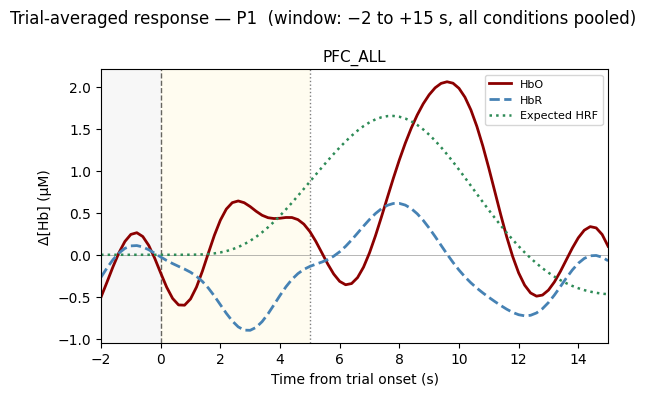

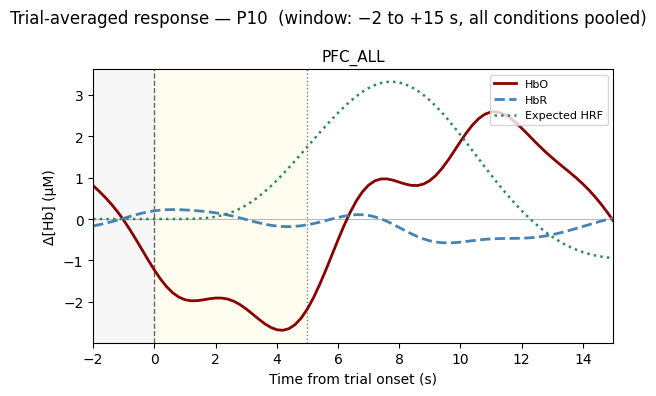

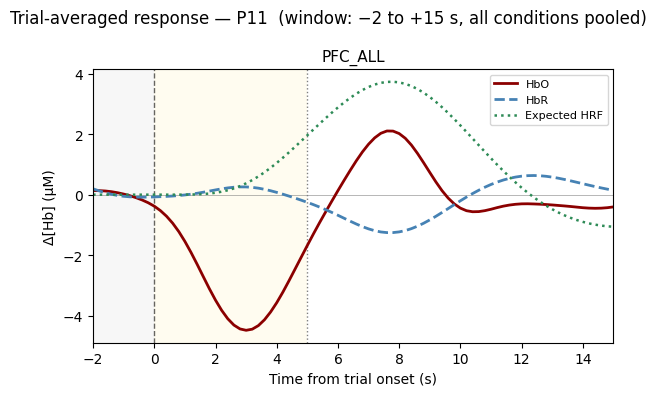

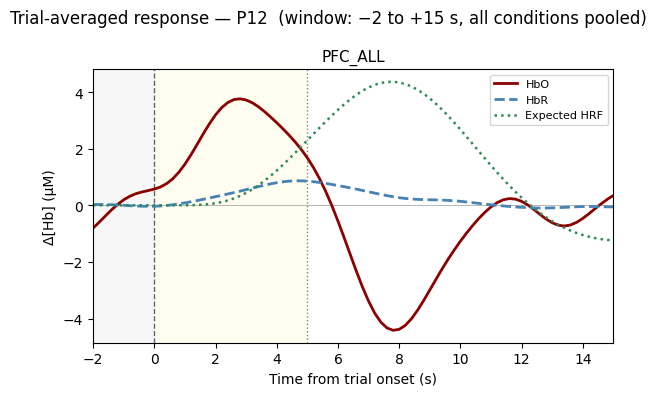

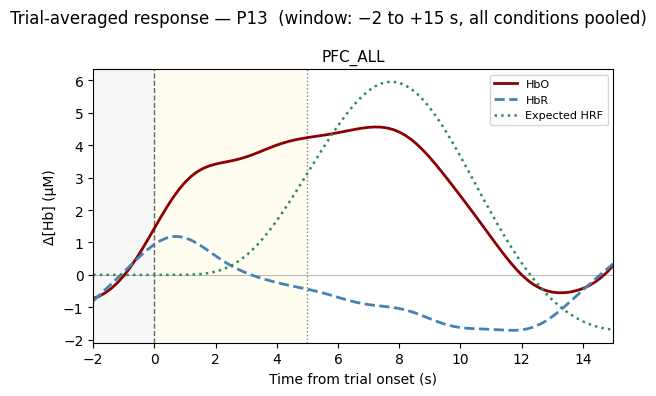

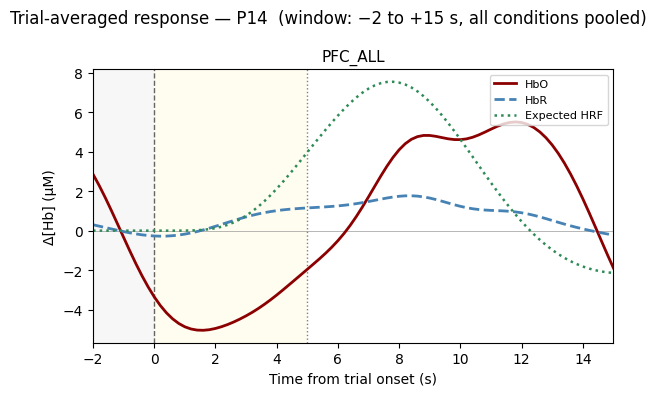

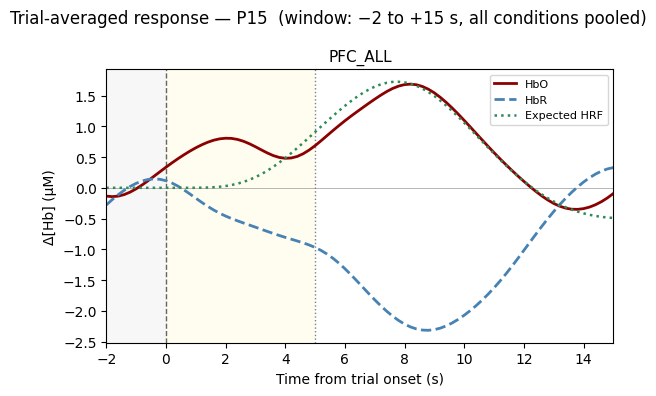

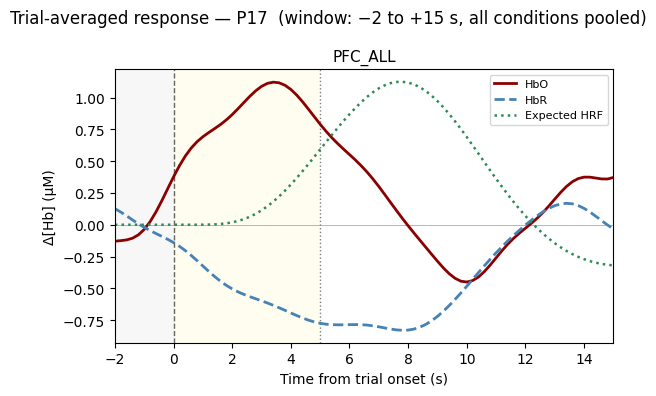

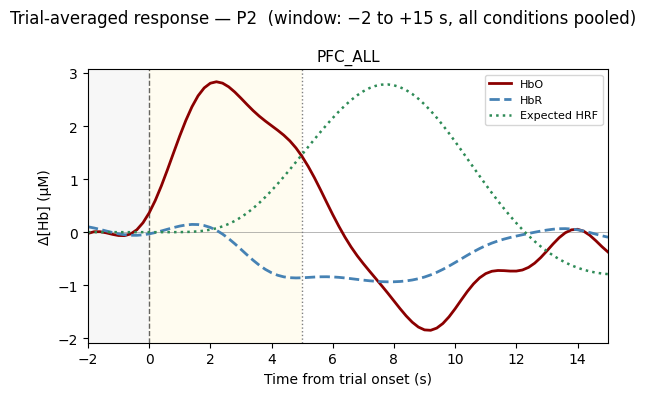

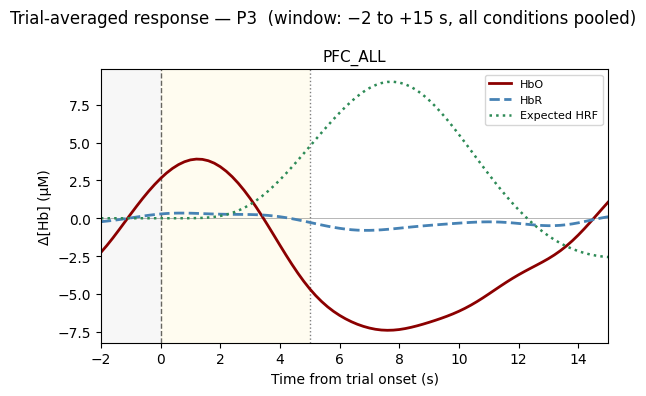

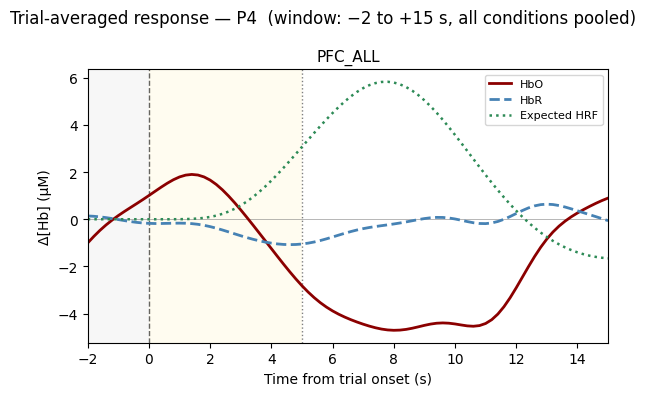

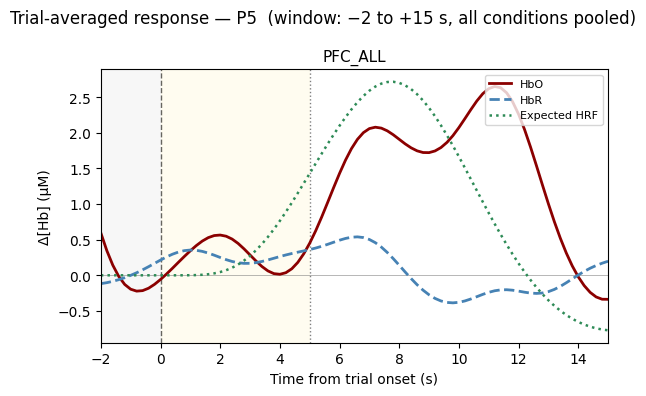

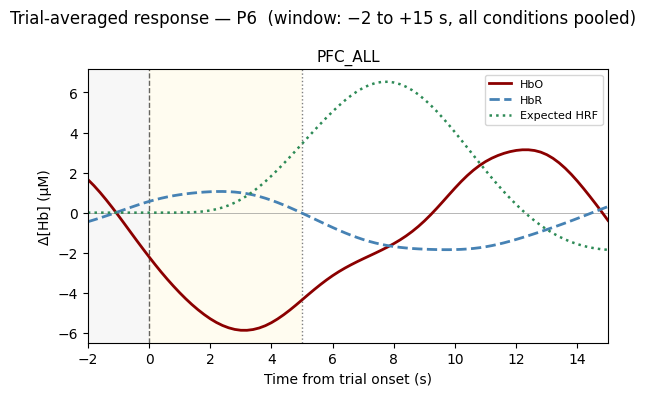

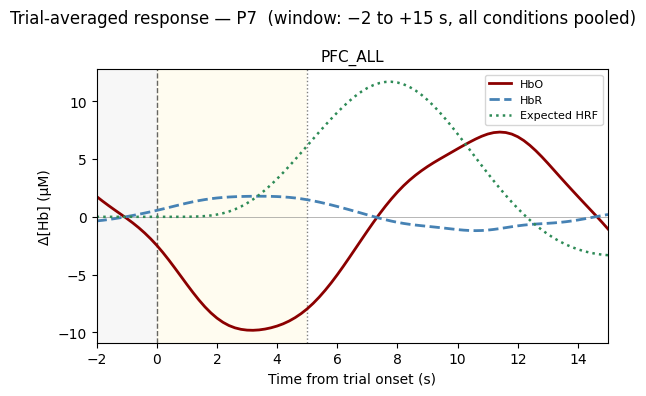

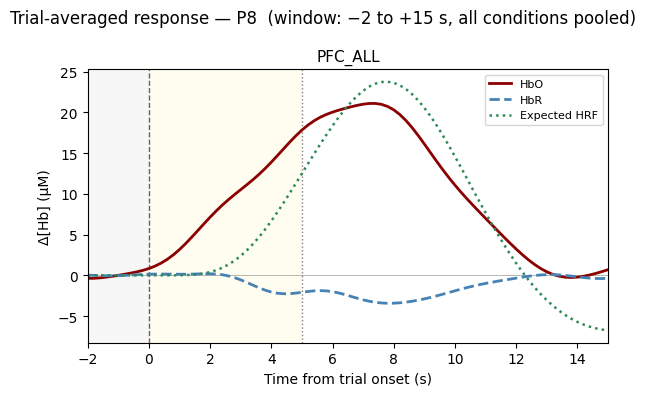

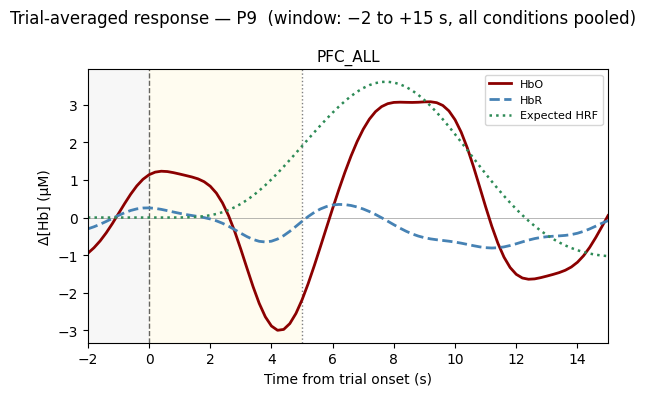

In [4]:
# One figure per subject, 2×2 grid (ROIs).
# Dark red solid = HbO grand average; steelblue dashed = HbR grand average.
# Green dotted = Glover HRF for a 5-s stimulus, scaled to HbO RMS per subplot.

_hrf_raw, _ = compute_regressor(
    (np.array([0.0]), np.array([TRIAL_DUR_SEC]), np.array([1.0])),
    'glover', t_axis, min_onset=-PRE_TRIAL_SEC,
)
hrf_shape = _hrf_raw.ravel()
_rms_hrf  = np.sqrt(np.mean(hrf_shape ** 2))

roi = "PFC_ALL"
for subject in subject_list:
    fig, ax = plt.subplots(figsize=(6, 4))
    fig.suptitle(
        f'Trial-averaged response — {subject}  '
        f'(window: −{PRE_TRIAL_SEC:.0f} to +{POST_TRIAL_SEC:.0f} s, '
        f'all conditions pooled)',
        fontsize=12,
    )

    ax.axvspan(-PRE_TRIAL_SEC, 0, alpha=0.06, color='grey', lw=0)
    ax.axvspan(0, TRIAL_DUR_SEC, alpha=0.06, color='gold', lw=0)
    ax.axvline(0, color='black', lw=1.0, ls='--', alpha=0.6)
    ax.axvline(TRIAL_DUR_SEC, color='black', lw=1.0, ls=':', alpha=0.5)
    ax.axhline(0, color='grey', lw=0.4)

    hbo = subject_evoked[subject]['hbo'][roi]
    hbr = subject_evoked[subject]['hbr'][roi]

    if not np.all(np.isnan(hbo)):
        ax.plot(t_axis, hbo, color='darkred', lw=2.0, label='HbO')
    if not np.all(np.isnan(hbr)):
        ax.plot(t_axis, hbr, color='steelblue', lw=2.0, ls='--', label='HbR')

    # Scale HRF to HbO RMS for this subject × ROI
    rms_data = np.sqrt(np.nanmean(hbo ** 2)) if not np.all(np.isnan(hbo)) else 0.0
    scale    = (rms_data / _rms_hrf) if (_rms_hrf > 0 and rms_data > 0) else 1.0
    ax.plot(t_axis, hrf_shape * scale,
            color='seagreen', lw=1.8, ls=':', label='Expected HRF')

    ax.set_xlim(-PRE_TRIAL_SEC, POST_TRIAL_SEC)
    ax.set_xlabel('Time from trial onset (s)')
    ax.set_ylabel('Δ[Hb] (µM)')
    ax.set_title(roi, fontsize=11)
    ax.legend(fontsize=8, loc='upper right')

    plt.tight_layout()
    plt.show()

# Group average

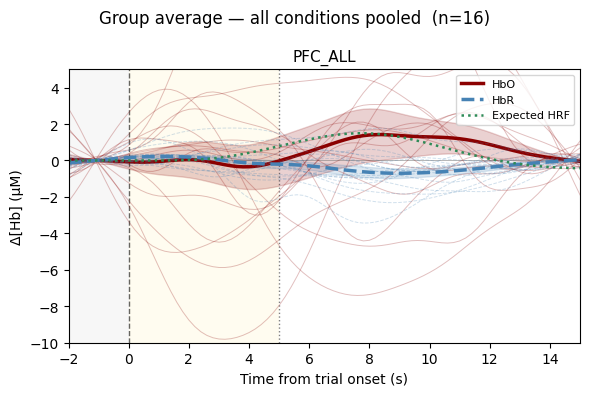

In [5]:
# One figure, 2×2 grid (ROIs).
# Thin lines = individual subjects; bold = grand mean ± SEM.
# Dark red / steelblue for HbO / HbR; green dotted = expected HRF.

n_subj = len(subject_list)

fig, ax = plt.subplots(figsize=(6, 4))
fig.suptitle(
    f'Group average — all conditions pooled  (n={n_subj})',
    fontsize=12,
)

roi = "PFC_ALL"
ax.axvspan(-PRE_TRIAL_SEC, 0, alpha=0.06, color='grey', lw=0)
ax.axvspan(0, TRIAL_DUR_SEC, alpha=0.06, color='gold', lw=0)
ax.axvline(0, color='black', lw=1.0, ls='--', alpha=0.6)
ax.axvline(TRIAL_DUR_SEC, color='black', lw=1.0, ls=':', alpha=0.5)
ax.axhline(0, color='grey', lw=0.4)

for chroma, color, ls in [('hbo', 'darkred', '-'), ('hbr', 'steelblue', '--')]:
    segs = np.array([subject_evoked[s][chroma][roi] for s in subject_list])

    # Individual subject traces
    for seg in segs:
        if not np.all(np.isnan(seg)):
            ax.plot(t_axis, seg, color=color, lw=0.7, alpha=0.25, ls=ls)

    # Grand mean ± SEM
    grand_mean = np.nanmean(segs, axis=0)
    grand_sem  = np.nanstd(segs, axis=0) / np.sqrt(np.sum(~np.isnan(segs[:, 0])))
    label = 'HbO' if chroma == 'hbo' else 'HbR'
    ax.plot(t_axis, grand_mean, color=color, lw=2.5, ls=ls, label=label)
    ax.fill_between(t_axis, grand_mean - grand_sem, grand_mean + grand_sem,
                    color=color, alpha=0.18)

# Scale HRF to grand-mean HbO RMS
hbo_grand = np.nanmean(
    [subject_evoked[s]['hbo'][roi] for s in subject_list], axis=0)
rms_data = np.sqrt(np.nanmean(hbo_grand ** 2))
scale    = (rms_data / _rms_hrf) if (_rms_hrf > 0 and rms_data > 0) else 1.0
ax.plot(t_axis, hrf_shape * scale,
        color='seagreen', lw=1.8, ls=':', label='Expected HRF')

ax.set_xlim(-PRE_TRIAL_SEC, POST_TRIAL_SEC)
ax.set_ylim(-10, 5)
ax.set_xlabel('Time from trial onset (s)')
ax.set_ylabel('Δ[Hb] (µM)')
ax.set_title(roi, fontsize=11)
ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()

# Conclusion

Some subjects might be more misaligned than others, but most have expected anticorrelation of HbO/HbR, and on average we end up with a curve that follows the expected HRF. This means that our estimates are somewhat uncertain, but will still be informative of how the experimental conditions affect hemodynamic response.